<h1 style="text-align: center;">Modèle Vélib : Projet File d'Attente</h1>

# 1. Modélisation : Construire le modèle.
On cherche à simuler la probabilité stationnaire qu'une station Vélib' soit vide à l'état stationnaire.

On fait une hypothèse simplificatrice:
- Une station de vélos peut accepter un nombre infini de vélos (ie elle a une capacité infinie)

On note N le nombre total de vélos et J le nombre total de stations dans le système. N et J sont fixés et ne varient pas dans le modèle.

On note $ X = (X(t), t \geq 0)$ le processus qui représente le nombre de vélos par station et en trajet entre deux stations.

On note E l'ensemble d'état qu'on définit comme suit:

$$

E := \{ (n_{jk})_{j,k \in \llbracket 1, J \rrbracket} \ \text{ | } \Sigma_{j,k}{n_{j,k}} = N,  n_{jk} \geq 0 \}

$$

On a donc pour un état $n \in E$ :

$$
n = (n_{jk})_{j,k} \in E
$$

- $n_{jj} = $ nombre de vélos disponibles à une station $j$

- $n_{jk} = $ nombre de vélos entrain d'effectuer un trajet de la station $j$ à la station $k$

Pour chaque station $j$:
* Les utilisateurs (cyclistes) arrivent à la station $j$ selon un processus de Poisson d'intensité $\lambda_j$
* Quand un utilisateur arrive à la station $j$:
    - Si $n_{jj} > 0$ alors il prend un vélo.
    - Sinon il repart sans vélo.
* Donc $ \mathbf{1}_{\{n_{jj} > 0\}} $

On note $p_{jk}$ la probabilité qu'un client prenant un vélo à la station $j$ va à la station $k$ avec

$$
    p_{jk} \geq 0, \text{   } p_{jj} = 0, \text{   } \forall j \in \{1,\dots,J\} \text{  }\Sigma_{k \neq j}{p_{jk}} = 1
$$

On a donc l'amincissement d'un processus de poisson en $J-1$ processus de poisson d'intensité $\lambda_j p_{jk} \mathbf{1}_{ \{ n_{jj} > 0 \} }$

Finalement, pour chaque station $j$, chaque station $k \neq j$, les arrivées des utilisateurs qui effectuent le trajet $j \to k$ suivent un processus de Poisson d'intensité $\lambda_j p_{jk} \mathbf{1}_{ \{ n_{jj} > 0 \} }$

Soit $j \in \{1,\dots,J\}$ et $k \in \{1,\dots,J\}, k \neq j$. Alors la durée du trajet de vélo de la station $j$ à la station $k$ suit une loi exponentielle de paramètre $\mu_{jk} \mathbf{1}_{\{n_{jk} > 0\}}$

On a donc défini un closed migration system comme dans le livre de Kelly et Yudovina.

On définit ensuite l'opérateur de transition $T$ par:

1. Les fonctions de transition $T^{D}_{jk}$ qui représentent le départ d'un vélo de la station j à l'état de "effectuant le trajet $j \to k$".

$$
T^{D}_{jk}(n) = n - e_{jj} + e_{jk}
$$

2. Les fonctions de transition $T^{A}_{jk}$ qui représentent l'arrivée d'un vélo effectuant le trajet $j \to k$ à la station k.

$$
T^{A}_{jk}(n) = n - e_{jk} + e_{kk}
$$

Et on a donc les taux de transition suivants:

Soit $n \in E$. Soit $j,k \in \{1,\dots,J\}, j \neq k$.

1. Taux de transition de départ

$$
q(n, T^{D}_{jk}(n)) = \lambda_j p_{jk} \mathbf{1}_{\{n_{jj} > 0\}}
$$

2. Taux de transition d'arrivée

$$
q(n, T^{A}_{jk}(n)) = \mu_{jk} \mathbf{1}_{\{n_{jk} > 0\}}
$$

Pour calculer la distribution stationnaire, on introduit des variables $(\alpha_{jk})_{j,k}$ qui constitutent les variables des équations de traffic.

On définit les $(\alpha_{jk})$ de la manière suivante:

$$
\alpha_{jk} > 0, \; \; \; \; \; \; \Sigma_{k,j}^{J}{\alpha_{jk} = 1}
$$

Et on a donc les équations de traffic:

$$
\forall j \in {1,\dots,J}, \; \; \; \; \; \alpha_{jj} \Sigma_{k \neq j}^J{\mu_{kj}} = \Sigma_{k \neq j}^J{\alpha_{jk} \lambda_j p_{jk}}
$$

$$
\forall j,k \in {1,\dots,J}, j \neq k, \; \; \; \; \; \alpha_{jk} \lambda_j p_{jk} = \alpha_{kk} \mu_{jk}
$$

On doit donc résoudre ce système d'équations. Ce qui nous donne les $(\alpha_{jk})_{j,k}$ et ensuite on applique le théorème suivant pour les closed migration systems:

$$
\pi(n) = \frac{\Pi_{j,k}{{\alpha_{jk}^{n_{jk}}}}}{G_N}
$$

Avec $G_N$ la constante de normalisation.

In [ ]:
import numpy as np
import pandas as pd
from collections import defaultdict # On l'utilise pour avoir une table de hachage particulière qui assigne la valeur 0 aux clés manquantes. On utilise cette table de hachage pour calculer la probabilité stationnaire.
import matplotlib.pyplot as plt

In [3]:
def remplir_e(filename1="data/nombre_de_velos_disponibles_un_seul_velo.csv", filename2="data/nombre_de_velos_par_routes_un_seul_velo.csv"):
    '''
    Fonction qui permet de remplir l'état initial du système avec les données fournies.
    '''
    df1 = pd.read_csv(filename1)
    df2 = pd.read_csv(filename2)
    n = df1.to_numpy()[0]
    e = df2.to_numpy()
    for j in range(len(e)):
        e[j][j] = n[j]
    return e

def remplir_P(filename="data/matrice_de_routage.csv"):
    '''
    Fonction qui permet de remplir les p_jk avec la matrice de routage.
    '''
    df = pd.read_csv(filename)
    return df.to_numpy()


def remplir_lambda_(filename="data/nombre_de_departs_par_minute.csv"): 
    '''
    Fonction qui permet de remplir les lambda_j avec le nombre de départs par minute. (On est déjà homogène à un temps^-1).
    '''
    df = pd.read_csv(filename)
    lambda_ = df.to_numpy()
    return lambda_[0]
    
def remplir_mu_(filename="data/temps_de_traversee_en_minutes.csv"):
    '''
    Fonction qui permet de remplir les mu_{jk} avec le temps de traversée en minutes.
    '''
    df = pd.read_csv(filename)
    mu_ = df.to_numpy(dtype=float)
    for j in range(len(mu_)):
        for k in range(len(mu_)):
            if mu_[j][k] != 0:
                mu_[j][k] = 1/mu_[j][k] # Les données sont homogènes à des temps ; donc, pour que ce soit bien un paramètre d'une loi exponentielle, il doit être homogène à des temps^-1.
    return mu_

# 2. Analyse théorique : Étudier la probabilité stationnaire pour 1 vélo et 5 stations
Vu qu'on a un seul vélo, pour simplifier les notations, à la place d'écrire tout l'état $X(t)$, on note seulement l'indice $n_{j,k}$ où le vélo se trouve. Par exemple, s'il est à la station $2$ alors, on note $n_{2,2}$. S'il est sur le trajet $3 \to 4$ alors on note $n_{3,4}$.

Donc
$$
E = \{(j,k) \in \{1,2,3,4,5\}^2\}
$$

On reprend les mêmes notations qu'avant : $\mu_{jk}$, $\lambda_j$, $p_{jk}$.

Soit $j \in {1,2,3,4,5}$. Soit $k \neq j$:

$$
T^D_{jk}(n_{jj}) = n_{jk} \; \; \; \; \; q(n_{jj}, T^D_{jk}(n_{jj})) = \lambda_j p_{jk}
$$


$$
T^A_{jk}(n_{jk}) = n_{kk} \; \; \; \; \; q(n_{jk}, T^A_{jk}(n_{jk}) = n_{kk}) = \mu_{jk}
$$

On doit donc résoudre le système d'équation suivant:

$$
\begin{cases}

\mu_{12} \alpha_{12} = \lambda_1 P_{12} \alpha_{11}, \\
\mu_{13} \alpha_{13} = \lambda_1 P_{13} \alpha_{11}, \\
\mu_{14} \alpha_{14} = \lambda_1 P_{14} \alpha_{11}, \\
\mu_{15} \alpha_{15} = \lambda_1 P_{15} \alpha_{11}, \\[0.5em]

\mu_{21} \alpha_{21} = \lambda_2 P_{21} \alpha_{22}, \\
\mu_{23} \alpha_{23} = \lambda_2 P_{23} \alpha_{22}, \\
\mu_{24} \alpha_{24} = \lambda_2 P_{24} \alpha_{22}, \\
\mu_{25} \alpha_{25} = \lambda_2 P_{25} \alpha_{22}, \\[0.5em]

\mu_{31} \alpha_{31} = \lambda_3 P_{31} \alpha_{33}, \\
\mu_{32} \alpha_{32} = \lambda_3 P_{32} \alpha_{33}, \\
\mu_{34} \alpha_{34} = \lambda_3 P_{34} \alpha_{33}, \\
\mu_{35} \alpha_{35} = \lambda_3 P_{35} \alpha_{33}, \\[0.5em]

\mu_{41} \alpha_{41} = \lambda_4 P_{41} \alpha_{44}, \\
\mu_{42} \alpha_{42} = \lambda_4 P_{42} \alpha_{44}, \\
\mu_{43} \alpha_{43} = \lambda_4 P_{43} \alpha_{44}, \\
\mu_{45} \alpha_{45} = \lambda_4 P_{45} \alpha_{44}, \\[0.5em]

\mu_{51} \alpha_{51} = \lambda_5 P_{51} \alpha_{55}, \\
\mu_{52} \alpha_{52} = \lambda_5 P_{52} \alpha_{55}, \\
\mu_{53} \alpha_{53} = \lambda_5 P_{53} \alpha_{55}, \\
\mu_{54} \alpha_{54} = \lambda_5 P_{54} \alpha_{55}, \\[1em]

\alpha_{11}(\lambda_1 P_{12} + \lambda_1 P_{13} + \lambda_1 P_{14} + \lambda_1 P_{15}) = \mu_{21}\alpha_{21} + \mu_{31}\alpha_{31} + \mu_{41}\alpha_{41} + \mu_{51}\alpha_{51}, \\[0.5em]

\alpha_{22}(\lambda_2 P_{21} + \lambda_2 P_{23} + \lambda_2 P_{24} + \lambda_2 P_{25}) = \mu_{12}\alpha_{12} + \mu_{32}\alpha_{32} + \mu_{42}\alpha_{42} + \mu_{52}\alpha_{52}, \\[0.5em]

\alpha_{33}(\lambda_3 P_{31} + \lambda_3 P_{32} + \lambda_3 P_{34} + \lambda_3 P_{35}) = \mu_{13}\alpha_{13} + \mu_{23}\alpha_{23} + \mu_{43}\alpha_{43} + \mu_{53}\alpha_{53}, \\[0.5em]

\alpha_{44}(\lambda_4 P_{41} + \lambda_4 P_{42} + \lambda_4 P_{43} + \lambda_4 P_{45}) = \mu_{14}\alpha_{14} + \mu_{24}\alpha_{24} + \mu_{34}\alpha_{34} + \mu_{54}\alpha_{54}, \\[1em]

\Sigma_{i=1}^{5}{\Sigma_{j=1}^{5}{\alpha_{ij}}} = 1

\end{cases}
$$

Et en appliquant le théorème qui donne la distribution stationnaire on a :

$$
\pi(n_{jk}) = \frac{\alpha_{jk}}{G_5}
$$

Avec $G_5$ la constante de normalisation.


Donc pour avoir la probabilité qu'une station soit vide à l'état stationnaire on a la formule suivante puisqu'il n'y a qu'un seul vélo:

$$
\mathbb{P}(\text{Station j soit vide à l'état stationnaire}) = 1 - \pi(n_{jj})
$$

Pour résoudre ces équations on l'écrit sous forme matricielle $AX = b$ où $X = (\alpha_{jk})_{j,k}$. Puis on le résout numériquement.

In [4]:
# La fonction build_A_b a été faite par ChatGPT.
def build_A_b(lambda_, mu, P):
    '''
    On construit les matrices A et b pour résoudre numériquement le système AX = b.
    '''

    J = 5
    A = np.zeros((25, 25), dtype=float)
    b = np.zeros(25, dtype=float)

    def idx(j, k):
        '''
        Une fonction qui renvoie l'indice linéarisé (passage d'un indice 2D à un indice 1D).
        '''
        return j * J + k

    row = 0

    # 20 premières équations du type : mu[j,k] * a_jk - lambda[j] * P[j,k] * a_jj = 0
    for j in range(J):
        for k in range(J):
            if j != k:
                A[row, idx(j, j)] = -lambda_[j] * P[j, k]
                A[row, idx(j, k)] =  mu[j, k]
                row += 1

    # Les 4 équations du type : a_jj * sum_{k!=j} lambda[j] P[j,k] - sum_{i!=j} mu[i,j] a_ij = 0
    for j in range(4):   # Seulement 4 équations indépendantes.
        s_out = sum(lambda_[j] * P[j, k] for k in range(J) if k != j)
        A[row, idx(j, j)] = s_out

        for i in range(J):
            if i != j:
                A[row, idx(i, j)] = -mu[i, j]

        row += 1

    # Condition de normalisation.
    A[row, :] = 1.0
    b[row] = 1.0

    return A, b

# Fin de l'utilisation de l'IA.

lambda_ = remplir_lambda_()
mu_ = remplir_mu_()
P = remplir_P()

A, b = build_A_b(lambda_, mu_, P)

x = np.linalg.solve(A, b) # Avec NumPy, on résout le système AX = b.
alpha = x.reshape(5, 5) # On délinéarise alpha, qui est maintenant sous la forme d'un tableau 2D avec des indices j, k.

# On calcule la probabilité stationnaire, donc d'abord la constante de normalisation G_N.
G_N = 0 
for j in range(5):
    for k in range(5):
        G_N += alpha[j][k]
        
# G_N = 1
        
#for j in range(5):
    #print(f"π({j}) = {alpha[j][j]}")
    
# On renvoie les probabilités qu'une station soit vide à l'état stationnaire.
for j in range(5):
    print(f"P(Station {j} soit vide à l'état stationnaire) = {1 - alpha[j][j]}")

P(Station 0 soit vide à l'état stationnaire) = 0.8245327229415772
P(Station 1 soit vide à l'état stationnaire) = 0.8444956480293759
P(Station 2 soit vide à l'état stationnaire) = 0.8654753785824558
P(Station 3 soit vide à l'état stationnaire) = 0.8443318435447873
P(Station 4 soit vide à l'état stationnaire) = 0.8407257697976377


Les résultats semblent être cohérents à première vue puisqu'il y a un seul vélo donc la majorité du temps les stations sont vides.

# 3. Simulation : Écrire le programme et vérifier la correspondance entre théorie et simulation.

On cherche maintenant la loi du temps pendant lequel $X$ reste dans l'état $X(t) = n$. D'après le schéma précédent, $X$ change d'état lorsque le premier évènement arrive, donc:

$$
\text{min}((\mathcal{E}(\mu_{jk} \mathbf{1}_{\{ n_{jk} > 0 \}}))_{j \neq k}, (\mathcal{E}( \lambda_j p_{jk} \mathbf{1}_{\{ n_{jj} > 0\}}))_{j \neq k} )
$$

Donc le temps de séjour suit la loi 

$$ 
\mathcal{E}( \Sigma_{j=1}^J{ \Sigma_{k \neq j}{\mu_{jk} \mathbf{1}_{\{ n_{jk} > 0 \}} + \lambda_j p_{jk} \mathbf{1}_{\{ n_{jj} > 0\}}} }) 
$$

1. La probabilité d'aller à l'état $T^{D}_{jk}(n)$

$$

\frac{\lambda_j p_{jk} \mathbf{1}_{\{ n_{jj} > 0\}}}{\Sigma_{j=1}^J{ \Sigma_{k \neq j}{\mu_{jk} \mathbf{1}_{\{ n_{jk} > 0 \}} + \lambda_j p_{jk} \mathbf{1}_{\{ n_{jj} > 0\}}} }}

$$


2. La probabilité d'aller à l'état $T^{A}_{jk}(n)$

$$

\frac{\mu_{jk} \mathbf{1}_{\{ n_{jk} > 0 \}}}{\Sigma_{j=1}^J{ \Sigma_{k \neq j}{\mu_{jk} \mathbf{1}_{\{ n_{jk} > 0 \}} + \lambda_j p_{jk} \mathbf{1}_{\{ n_{jj} > 0\}}} }}

$$

Ainsi pour avoir la distribution stationnaire $\pi$, il suffit pour chaque état de calculer le temps total passé dans cet état et de diviser par la durée de la simulation soit:

$$
\pi(n) = \frac{\text{temps passé dans l'état } n}{\text{durée de la simulation}}
$$

Et pour avoir la probabilité qu'une station soit vide à l'état stationnaire il suffit de sommer le temps total lorsque la station est vide et de diviser par la durée de la simulation soit:

$$
\mathbb{P}(\text{Station j soit vide à l'état stationnaire}) = \frac{\text{temps passé où pour chaque état } n \text{ , } n_{jj} = 0}{\text{durée de la simulation}}
$$

In [ ]:
class Model:
    def __init__(self, J, horizon, nb_velo=1):
        self.J = J # Le nombre de stations
        self.horizon = horizon # La durée de la simulation
        if nb_velo == 1: # Si le nombre de vélo = 1 alors on utilise la data pour 1 vélo.
            self.e = remplir_e() # L'état initial
        else : # Sinon on utilise la data pour 100 vélos.
            self.e = remplir_e(filename1="data/nombre_de_velos_disponibles.csv",filename2="data/nombre_de_velos_par_routes.csv")
        self.mu_ = remplir_mu_() # Les valeurs des mu_jk
        self.P = remplir_P() # Les valeurs des p_jk
        self.lambda_ = remplir_lambda_() # Les valeurs de lambda_j
        self.proba_stat = defaultdict(int) # On instancie une table de hachage avec comme valeur par défaut 0 pour les clés manquantes. Les clés de ce tableau sont les états e et la valeur le temps de séjour dans chaque état pendant la simulation.
    
    def indicatrice(self, A):
        if A:
            return 1
        return 0
    
    def parametre_du_temps_de_sejour(self):
        '''
        Cette fonction renvoie le paramètre du temps de séjour selon l'état dans lequel nous sommes. Elle utilise la formule donnée juste avant.
        '''
        parametre = 0
        for j in range(self.J):
            for k in range(self.J):
                if j != k:
                    parametre += self.mu_[j][k] * self.indicatrice(self.e[j][k] > 0)
                    parametre += self.lambda_[j] * self.P[j][k] * self.indicatrice(self.e[j][j] > 0)
        return parametre
    
    def T(self, i, j, k):
        '''
        Cette fonction représente la fonction de transition et modifie l'état du système.
        '''
        if i == 'D': # Si on est dans le cas d'un départ T^D
            self.e[j][k] += 1 # + e_jk
            self.e[j][j] -= 1 # - e_jj
        if i == 'A': # Si on est dans le cas d'une arrivée T^A
            self.e[k][k] += 1 # + e_kk
            self.e[j][k] -= 1 # - e_jk
    
    def transition(self):
        '''
        Fonction qui calcule toutes les transitions possibles depuis l'état courant et leurs probabilités associées.
        '''
        etat_suivant = [[],[],[]] # Premier tableau = un indice pour le deuxième tableau. Car quand on applique la fonction np.random.choice(_,p), cela marche seulement avec des int et non des tuples | Le deuxième tableau est l'état possible, e.g. ('A',j,k). Le troisième tableau = probabilité associée à la transition dans cet état.
        i = 0
        for j in range(self.J):
            for k in range(self.J):
                # On parcourt toutes les paires de stations (j,k)
                if k != j: # On exclut les trajets d'une station à elle-même
                    etat_suivant[0].append(i)
                    etat_suivant[1].append(('A',j,k)) # Transition de type T^A
                    etat_suivant[2].append((self.mu_[j][k] * self.indicatrice(self.e[j][k] > 0))/self.parametre_du_temps_de_sejour()) # Probabilité associée
                    
                    i += 1
                    
                    etat_suivant[0].append(i)
                    etat_suivant[1].append(('D',j,k)) # Transition de type T^D
                    etat_suivant[2].append((self.lambda_[j] * self.P[j][k] * self.indicatrice(self.e[j][j] > 0))/self.parametre_du_temps_de_sejour()) # Probabilité associée.
                    
                    i += 1
                    
        return etat_suivant # On renvoie l'ensemble des états de transition possibles avec leurs probabilités associées.
    
    def simulation(self):
        '''
        Cette fonction permet de faire tourner la simulation.
        '''
        temps = 0
        while temps < self.horizon:
            etat_courant = tuple(map(tuple, self.e)) # Une table de hachage ne peut pas avoir un tableau comme clé, donc on la transforme en tuple de tuples.
            duree = np.random.exponential(1/self.parametre_du_temps_de_sejour()) # Temps de séjour dans l'état courant
            self.proba_stat[etat_courant] += duree # On ajoute dans la table de hachage le temps de séjour dans l'état courant
            temps += duree # On augmente le temps avec le temps passé dans l'état courant.
            
            a = self.transition() # Calcul des transitions possibles et de leurs probabilités.
            N = np.random.choice(a[0],p=a[2]) # Tirage aléatoire d'une transition avec a[0] les indices et a[2] les probabilités associées.
            N = a[1][N] # On la met sous la forme ('A' ou 'D', j, k) pour pouvoir appliquer la fonction de transition T
            self.T(N[0],N[1],N[2]) # On transitionne d'état.
            
    def probabilite_stationnaire(self):
        '''
        Calcule la distribution stationnaire mais renvoie aussi la probabilité stationnaire qu'une station j soit vide.
        '''
        values = list(self.proba_stat.values()) # On récupère toutes les durées de séjour dans chaque état.
        values = [x/self.horizon for x in values] # On divise par le temps de la simulation, ce qui nous donne la distribution stationnaire approximative.
        
        stations = [0 for j in range(self.J)]
        
        for j in range(self.J): # Pour chaque station j
            for k in self.proba_stat.keys(): # On regarde chaque état e possible
                if k[j][j] == 0: # Si la station est vide à l'état e 
                    stations[j] += self.proba_stat[k]/self.horizon # Alors on rajoute le temps passé dans cet état au temps total où la station j est vide
                    
        # Affichage
        for j in range(self.J):
            print(f"P(Station {j} est vide à l'état stationnaire) = {stations[j]}")
    
    def probabilite_stationnaire_dune_station_vide_graph(self):
        '''
        Fonction qui permet de tracer un graphe avec la probabilité à l'état stationnaire que chaque station soit vide.
        '''
        stations = [0 for j in range(self.J)]
        
        for j in range(self.J):
            for k in self.proba_stat.keys():
                if k[j][j] == 0: # Si à l'état k la station j est vide 
                    stations[j] += self.proba_stat[k]/self.horizon # Alors on rajoute son temps / horizon à sa probabilité stationnaire.
                                        
        x_label = [f"{j}" for j in range(self.J)]
                    
        plt.bar(x_label,stations)
        plt.xlabel('Station')
        plt.ylabel('Probabilité stationnaire que la station soit vide')
        plt.title('Distribution stationnaire')

        plt.show()

In [ ]:
model = Model(5, horizon=300000, nb_velo=1)
model.simulation()
model.probabilite_stationnaire()

On a donc des résultats très similaires ce qui confirme la correspondance entre la simulation et la théorie.

# 4. Exécution : Faire tourner le programme pour 100 vélos et 5 stations (paramètres fournis).

P(Station 0 est vide à l'état stationnaire) = 0
P(Station 1 est vide à l'état stationnaire) = 0.05841764891926991
P(Station 2 est vide à l'état stationnaire) = 0.17381198338915707
P(Station 3 est vide à l'état stationnaire) = 0.04431703690056958
P(Station 4 est vide à l'état stationnaire) = 0.012245429370131152


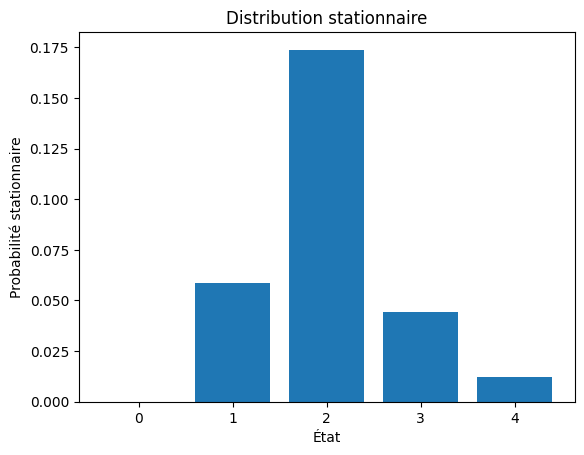

In [ ]:
model = Model(5, horizon=10000, nb_velo=100) # 5 stations
model.simulation() # On fait tourner la simulation
model.probabilite_stationnaire() # Affichage du résultat.
model.probabilite_stationnaire_dune_station_vide_graph() # Représentation graphique.